# Actividad 15. Implementación de técnicas de Programación Dinámica

| Dato | Información |
|---|---|
| Alumno | **Diego Navarro Sánchez** |
| No. de cuenta | **202497** |
| Materia | **Lenguajes de Computación** |
| Profesor(a) | **Paulo Vázquez** |

**Objetivo:** implementar las técnicas de Memoización (Top-Down) y Tabulación (Bottom-Up)
para el problema del corte de varillas y comparar su rendimiento contra la solución
recursiva pura.

*Las celdas del profesor se conservan tal cual. Lo agregado empieza en la sección de
Tabulación.*

## El Problema del corte de varillas (Rod Cutting Problem)

El problema consiste en que considerando una varilla de *n* pulgadas y una tabla de precios $p_n$ por pulgada, donde *i* = {1, 2, ..., n}, se pueda determinar el máximo ingreso por los cortes realizados o no, en la varilla.

Considerando el precio de cada corte en la varilla, es posible que no necesariamente se condisidere un corte.

### Tabla de precios por tamaño de corte

| Longitud (i) | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Precio | \$1 | \$5 | \$8 | \$9 | \$10 | \$17 | \$17 | \$20 | \$24 | \$30 |

Una variblla de *n* pulgadas se puede cortar de $2^{n-1}$ formas distintas, ya que cada pulgada *i* = {1, 2, ..., n-1} existen opciones para realizar los cortes.

### Solución recursiva (pura)

In [1]:
# importación de librerías
import time
import sys

In [2]:
# Acotamiento del tiempo de ejecución para los algoritmos recursivos
sys.setrecursionlimit(2000)

In [3]:
# Definición de la entrada constante
PRECIOS = (0, 1, 5, 8, 9, 10, 17, 17, 20, 24, 30)

In [4]:
# Implementación de la función recursiva pura
def cut_rod(p: list[int], n:int) -> int:
    """
    Función recursiva para calcular el máximo ingreso por los cortes realizados en una varilla de longitud n.
    """
    if n == 0:
        return 0
    q = -1
    for i in range(1, n+1):
      # Evaluar todas las opciones de corte inicial de tamaño i e invocando de manera recursiva a la función para calcular el máximo ingreso con el remanente
      precio_i = p[i] if i < len(p) else 0
      q = max(q, precio_i + cut_rod(p, n-i))
    return q

### Implementación de las técnicas de programación dinámica

Como se pudo indentificar previamente, en el peor de los casos el problema del cálculo de la máxima ganancia en el corte de una varilla, esta dado por $O(2^{n})$.

Justamente la programación dinámica, busca evitar la redundancia en el cálculo de algunos cortes que previamente ya fueron evaluados a través de la implementación ya sea de una memoria caché (arreglo) o bien de una tabla.

#### Memorización (Top-Down)

Este técnica reutiliza la misma función recursiva pura y agrega una caché para verificar si el resultado de un cálculo ya fue evaluado previamente, en cuyo caso recupera el valor almacenado ($O(1)$).

In [5]:
# Definición de la función de memoización
def cut_rod_memoized(p: list[int], n:int) -> int:
    """
    Función recursiva para calcular el máximo ingreso por los cortes realizados en una varilla de longitud n, implementando una función auxiliar de memoización
    """
    # Creación de un arreglo "r" de tamaño n+1 e inicilizado a -1 (valores desconocidos/no calculados)
    r = [-1] * (n+1)
    return cut_rod_aux(p, n, r)

def cut_rod_aux(p: list[int], n:int, r: list[int]) -> int:
    """
    Función auxiliar para la implementación de la técnica de memoización para verificar si el resultado de un cálculo ya fue evaluado previamente, en cuyo caso recupera el valor almacenado
    """
    # Verificación de resultado en memoria
    if r[n] >= 0:
      return r[n]

    # Caso de finalización/retorno
    if n==0:
      q=0
    else:
      q = -1
      for i in range(1, n+1):
        # Evaluar todas las opciones de corte inicial de tamaño i e invocando de manera recursiva a la función para calcular el máximo ingreso con el remanente
        precio_i = p[i] if i < len(p) else 0
        q = max(q, precio_i + cut_rod_aux(p, n-i, r))

    # Almacenamiento del resultado en memoria
    r[n] = q
    return q

#### Implementación de la técnica tabulación (Bottom-Up)

La tabulación resuelve los subproblemas **de menor a mayor**: primero el ingreso óptimo de
una varilla de longitud 0, luego de 1, 2, …, hasta n. Cuando se calcula `r[j]`, todos los
`r[j - i]` que necesita ya están en la tabla, así que no hay recursión ni pila de llamadas.
Dos ciclos anidados dan una complejidad de $O(n^2)$ en tiempo y $O(n)$ en memoria.

$$r_j = \max_{1 \le i \le j}\left(p_i + r_{j-i}\right), \qquad r_0 = 0$$

In [6]:
# Implementación de la técnica de tabulación (Bottom-Up)
def bottom_up_cut_rod(p: list[int], n: int) -> int:
    """
    Calcula el máximo ingreso para una varilla de longitud n llenando una tabla "r"
    desde el subproblema más pequeño (longitud 0) hasta n.
    """
    # Tabla de resultados: r[j] = máximo ingreso para una varilla de longitud j
    r = [0] * (n + 1)
    for j in range(1, n + 1):          # subproblemas en orden creciente
        q = -1
        for i in range(1, j + 1):      # primer corte de tamaño i
            precio_i = p[i] if i < len(p) else 0
            q = max(q, precio_i + r[j - i])   # r[j - i] ya fue calculado
        r[j] = q
    return r[n]

### Funciones adecuadas para conocer los cortes

Para saber **qué cortes** producen el ingreso máximo, cada técnica guarda además el
**primer corte óptimo** `s[j]` de cada subproblema. Los cortes se reconstruyen siguiendo
`s`: se corta `s[n]`, queda una varilla de `n - s[n]`, se corta `s[n - s[n]]`, y así hasta
llegar a 0.

Las tres versiones usan el mismo criterio de desempate (se queda con el primer corte que
mejora estrictamente el ingreso), así que reportan exactamente los mismos cortes.

In [7]:
def reconstruir_cortes(s: list[int], n: int) -> list[int]:
    """Recorre la tabla de primeros cortes s para obtener la lista de piezas."""
    cortes = []
    while n > 0:
        cortes.append(s[n])
        n -= s[n]
    return cortes


# 1) Recursiva pura, extendida para devolver también los cortes
def cut_rod_cortes(p: list[int], n: int) -> tuple[int, list[int]]:
    """Misma recursión que cut_rod: O(2^n). Devuelve (ingreso máximo, cortes)."""
    if n == 0:
        return 0, []
    q, mejores = -1, []
    for i in range(1, n + 1):
        precio_i = p[i] if i < len(p) else 0
        q_resto, cortes_resto = cut_rod_cortes(p, n - i)
        if precio_i + q_resto > q:
            q, mejores = precio_i + q_resto, [i] + cortes_resto
    return q, mejores


# 2) Memoización (Top-Down), extendida con la tabla de primeros cortes s
def cut_rod_memoized_cortes(p: list[int], n: int) -> tuple[int, list[int]]:
    """Misma recursión con caché r (ingresos) y s (primer corte óptimo): O(n^2)."""
    r = [-1] * (n + 1)
    s = [0] * (n + 1)

    def aux(m: int) -> int:
        if r[m] >= 0:                  # resultado ya calculado: O(1)
            return r[m]
        if m == 0:
            q = 0
        else:
            q = -1
            for i in range(1, m + 1):
                precio_i = p[i] if i < len(p) else 0
                valor = precio_i + aux(m - i)
                if valor > q:
                    q, s[m] = valor, i
        r[m] = q
        return q

    return aux(n), reconstruir_cortes(s, n)


# 3) Tabulación (Bottom-Up), extendida con la tabla de primeros cortes s
def bottom_up_cut_rod_cortes(p: list[int], n: int) -> tuple[int, list[int]]:
    """Llenado iterativo de r y s desde 0 hasta n: O(n^2), sin recursión."""
    r = [0] * (n + 1)
    s = [0] * (n + 1)
    for j in range(1, n + 1):
        q = -1
        for i in range(1, j + 1):
            precio_i = p[i] if i < len(p) else 0
            if precio_i + r[j - i] > q:
                q, s[j] = precio_i + r[j - i], i
        r[j] = q
    return r[n], reconstruir_cortes(s, n)

### Verificación

In [8]:
# Las tres técnicas (y sus versiones con cortes) deben dar el mismo ingreso para todo n
for n in range(0, 21):
    esperado = cut_rod(PRECIOS, n)
    assert cut_rod_memoized(PRECIOS, n) == esperado
    assert bottom_up_cut_rod(PRECIOS, n) == esperado
    resultados = {cut_rod_cortes(PRECIOS, n)[0], cut_rod_memoized_cortes(PRECIOS, n)[0],
                  bottom_up_cut_rod_cortes(PRECIOS, n)[0]}
    assert resultados == {esperado}, (n, resultados)
    # Los cortes deben sumar n y producir exactamente el ingreso reportado
    ingreso, cortes = bottom_up_cut_rod_cortes(PRECIOS, n)
    assert sum(cortes) == n
    assert sum(PRECIOS[i] if i < len(PRECIOS) else 0 for i in cortes) == ingreso
    assert cut_rod_cortes(PRECIOS, n)[1] == cut_rod_memoized_cortes(PRECIOS, n)[1] == cortes

# Casos conocidos de la tabla de precios
assert bottom_up_cut_rod_cortes(PRECIOS, 4) == (10, [2, 2])
assert bottom_up_cut_rod_cortes(PRECIOS, 10) == (30, [10])
print("✔ Las tres técnicas coinciden en ingreso y cortes para n = 0..20")

✔ Las tres técnicas coinciden en ingreso y cortes para n = 0..20


#### Benchmark de las 3 técnicas

Elabora una tabla que compare los tiempos para el cálculo de los ingresos máximos utilizando las tres técnicas, y adecuando las funciones para conocer cuáles serían los cortes.

Se miden las versiones **con cortes** de las tres técnicas con `time.perf_counter()`:

* **Recursiva**: se repite 5 veces para n ≤ 20. Para n ≥ 25 se ejecuta **una sola vez**,
  porque cada corrida tarda de segundos a minutos. Con n = 30 hace 2²⁹ ≈ 537 millones de
  llamadas.
* **Memoización y tabulación**: tardan microsegundos, así que se repiten 2,000 veces y se
  reporta el promedio por ejecución.

⏱ **Esta celda tarda varios minutos** (≈ 5–10 min, casi todo en la recursiva con
n = 28 y n = 30). Para una prueba rápida, cambia `INCLUIR_RECURSIVO_GRANDE = False`.

In [9]:
import statistics
import pandas as pd

LONGITUDES = [5, 10, 15, 20, 25, 28, 30]
INCLUIR_RECURSIVO_GRANDE = True      # False: omite la recursiva para n >= 25
REPS_DP = 2000

def medir_ms(funcion, n, repeticiones):
    """Tiempo promedio por ejecución, en milisegundos."""
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        resultado = funcion(PRECIOS, n)
    return (time.perf_counter() - t0) * 1000 / repeticiones, resultado

filas = []
for n in LONGITUDES:
    t_memo, (ingreso, cortes) = medir_ms(cut_rod_memoized_cortes, n, REPS_DP)
    t_tab, res_tab = medir_ms(bottom_up_cut_rod_cortes, n, REPS_DP)
    if n <= 20 or INCLUIR_RECURSIVO_GRANDE:
        t_rec, res_rec = medir_ms(cut_rod_cortes, n, 5 if n <= 20 else 1)
        assert res_rec == res_tab == (ingreso, cortes)
    else:
        t_rec = float("nan")
    filas.append({"Longitud de la varilla": n, "Recursivo (ms)": t_rec,
                  "Memoización (ms)": t_memo, "Tabulación (ms)": t_tab,
                  "Ingreso Máximo": ingreso,
                  "Cortes": " + ".join(map(str, cortes))})
    print(f"n = {n:>2} listo  (recursivo: {t_rec:,.1f} ms)")

tabla = pd.DataFrame(filas)
tabla.to_csv("benchmark_corte_varillas.csv", index=False)

n =  5 listo  (recursivo: 0.0 ms)
n = 10 listo  (recursivo: 0.2 ms)
n = 15 listo  (recursivo: 6.3 ms)


n = 20 listo  (recursivo: 233.1 ms)


n = 25 listo  (recursivo: 7,626.6 ms)


n = 28 listo  (recursivo: 56,056.7 ms)


n = 30 listo  (recursivo: 233,669.0 ms)


In [10]:
from IPython.display import Markdown, display

def fmt_ms(x):
    if x != x:                       # NaN: no se ejecutó
        return "omitido"
    return f"{x:,.3f}" if x < 10 else f"{x:,.1f}"

encabezado = ("| Longitud de la varilla | Recursivo (ms) | Memoización (ms) | Tabulación (ms) "
              "| Ingreso Máximo | Cortes |\n| --- | --- | --- | --- | --- | --- |\n")
renglones = "\n".join(
    f"| {r['Longitud de la varilla']} | {fmt_ms(r['Recursivo (ms)'])} | "
    f"{fmt_ms(r['Memoización (ms)'])} | {fmt_ms(r['Tabulación (ms)'])} | "
    f"${r['Ingreso Máximo']} | {r['Cortes']} |"
    for _, r in tabla.iterrows())
display(Markdown(encabezado + renglones))

| Longitud de la varilla | Recursivo (ms) | Memoización (ms) | Tabulación (ms) | Ingreso Máximo | Cortes |
| --- | --- | --- | --- | --- | --- |
| 5 | 0.006 | 0.005 | 0.002 | $13 | 2 + 3 |
| 10 | 0.161 | 0.008 | 0.005 | $30 | 10 |
| 15 | 6.301 | 0.014 | 0.009 | $43 | 2 + 3 + 10 |
| 20 | 233.1 | 0.030 | 0.015 | $60 | 10 + 10 |
| 25 | 7,626.6 | 0.035 | 0.024 | $73 | 2 + 3 + 10 + 10 |
| 28 | 56,056.7 | 0.044 | 0.027 | $82 | 2 + 6 + 10 + 10 |
| 30 | 233,669.0 | 0.048 | 0.031 | $90 | 10 + 10 + 10 |

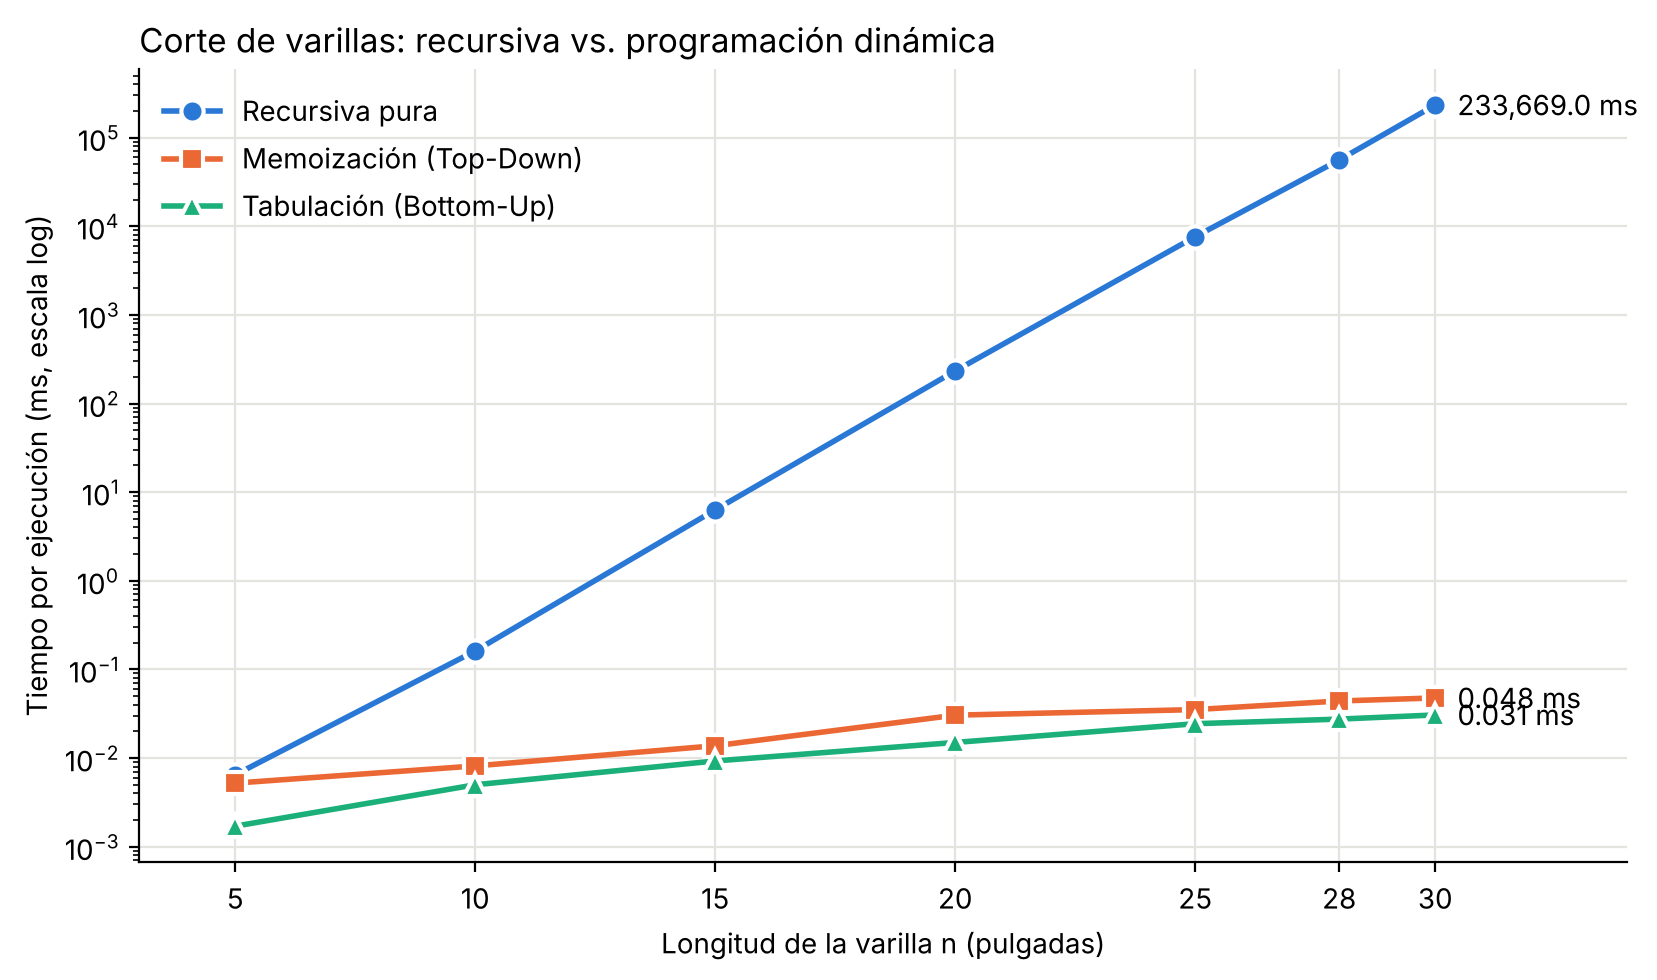

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 5))
series = [("Recursivo (ms)", "Recursiva pura", "#2a78d6", "o"),
          ("Memoización (ms)", "Memoización (Top-Down)", "#eb6834", "s"),
          ("Tabulación (ms)", "Tabulación (Bottom-Up)", "#1baf7a", "^")]
for col, etiqueta, color, marca in series:
    d = tabla.dropna(subset=[col])
    ax.plot(d["Longitud de la varilla"], d[col], color=color, lw=2, marker=marca, ms=8,
            markeredgecolor="white", markeredgewidth=1.5, label=etiqueta)
    ultimo = d.iloc[-1]
    ax.annotate(f"{fmt_ms(ultimo[col])} ms", (ultimo["Longitud de la varilla"], ultimo[col]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_yscale("log")
ax.set_xlim(3, 34)
ax.set_xticks(LONGITUDES)
ax.set_xlabel("Longitud de la varilla n (pulgadas)")
ax.set_ylabel("Tiempo por ejecución (ms, escala log)")
ax.set_title("Corte de varillas: recursiva vs. programación dinámica", loc="left")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.grid(True, color="#e4e3dd")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("benchmark_corte_varillas.png", dpi=150)
plt.show()

In [12]:
# Cifras para el análisis (se recalculan en cada ejecución)
t = tabla.set_index("Longitud de la varilla")
n_max = int(t["Recursivo (ms)"].last_valid_index())
rec, memo, tab = (t.loc[n_max, c] for c in ("Recursivo (ms)", "Memoización (ms)", "Tabulación (ms)"))
print(f"n = {n_max}: recursiva {rec:,.0f} ms | memoización {memo:.3f} ms | tabulación {tab:.3f} ms")
print(f"  → la tabulación es ≈ {rec / tab:,.0f} veces más rápida que la recursiva")
print(f"  → la tabulación es ≈ {memo / tab:.1f} veces más rápida que la memoización")
r = t["Recursivo (ms)"]
print(f"Crecimiento de la recursiva de n = 20 a n = 25: ×{r[25] / r[20]:.0f}  (2^5 = 32)")

n = 30: recursiva 233,669 ms | memoización 0.048 ms | tabulación 0.031 ms
  → la tabulación es ≈ 7,641,040 veces más rápida que la recursiva
  → la tabulación es ≈ 1.6 veces más rápida que la memoización
Crecimiento de la recursiva de n = 20 a n = 25: ×33  (2^5 = 32)


### Análisis de resultados

**Recursiva pura — $O(2^n)$.** La recursiva vuelve a resolver los mismos subproblemas una y
otra vez: una varilla de n pulgadas genera $2^{n-1}$ formas de cortarla y la función
explora todas. En la tabla, su tiempo se **multiplica por ≈ 2 con cada pulgada extra**
(≈ ×32 de n = 20 a n = 25). Con n = 30 pasa de milisegundos a minutos.

**Memoización (Top-Down) — $O(n^2)$.** Conserva la misma recursión, pero cada subproblema
`r[m]` se calcula **una sola vez** y las siguientes consultas cuestan $O(1)$. Solo hay
n + 1 subproblemas distintos y cada uno revisa hasta n cortes, de ahí $O(n^2)$. Con n = 30
tarda una fracción de milisegundo.

**Tabulación (Bottom-Up) — $O(n^2)$.** Tiene la misma complejidad que la memoización, pero
es **más rápida en la práctica**: no paga llamadas a función ni la pila de recursión (en
Python cada llamada es costosa) y no corre riesgo de superar el límite de recursión con n
grande. A cambio, resuelve **todos** los subproblemas de 1 a n aunque alguno no se
necesitara. En este problema se necesitan todos, así que no pierde nada.

**Cortes.** Las tres técnicas reportan el mismo ingreso y los mismos cortes. Como la pieza
de 10 pulgadas tiene el mejor precio por pulgada (\$3.00), las soluciones óptimas usan
piezas de 10 siempre que pueden y completan el resto con las siguientes piezas más
rentables: 6 (\$2.83/pulg.), 3 (\$2.67/pulg.) y 2 (\$2.50/pulg.). Por ejemplo,
n = 30 → 10 + 10 + 10 = \$90. Si hay varias combinaciones con el mismo ingreso, las
funciones devuelven la primera que encuentran.

### Conclusión

La programación dinámica convierte un problema exponencial en uno polinomial **guardando
resultados de subproblemas que se repiten**. La memoización es la forma más directa de
lograrlo partiendo de una recursión ya escrita, porque solo agrega una caché. La tabulación
requiere pensar el orden de los subproblemas, pero da el código más rápido y sin
recursión. Para n pequeño (≤ 10) cualquier técnica sirve. A partir de n ≈ 25 la recursiva
pura ya no es práctica.